# Modeling dan Evaluasi - Prakiraan PM2.5 Bandung (Kasus 06)

Data bersih (`data/clean.csv`) dan fungsi fitur (`src/features.py`) dibaca dari repo GitHub tim.
Pastikan keduanya sudah di-upload ke repo.

Urutan notebook ini:
1. Membuat fitur.
2. Membandingkan beberapa model dengan baseline persistence di data validation.
3. Memilih model dan threshold peringatan di data validation.
4. Melatih ulang model dengan data train dan validation, lalu menguji sekali di data test.
5. Menyimpan model ke `artifacts/`. Upload folder ini ke repo agar bisa dipakai aplikasi.

In [1]:
import json
import sys
import tempfile
import urllib.request
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

GITHUB_RAW = "https://raw.githubusercontent.com/alfdmsr/pm25-forecast-bandung/main"

# Unduh src/features.py dari GitHub ke folder sementara, lalu import
folder_src = Path(tempfile.gettempdir()) / "pm25_src"
folder_src.mkdir(exist_ok=True)
urllib.request.urlretrieve(f"{GITHUB_RAW}/src/features.py", folder_src / "features.py")
sys.path.insert(0, str(folder_src))
from features import FITUR, FITUR_RIWAYAT, STASIUN, buat_fitur, fitur_dari_input, kategori_pm25

df_clean = pd.read_csv(f"{GITHUB_RAW}/data/clean.csv", parse_dates=["waktu"])
print(df_clean.shape)

(87252, 8)


## 1. Membuat fitur

In [2]:
data = buat_fitur(df_clean).dropna(subset=["target_pm25"])
print("fitur:", FITUR)
data[["waktu", "stasiun", "pm25_ugm3", "pm25_lag1", "target_time", "target_pm25"]].head()

fitur: ['pm25_ugm3', 'suhu_C', 'kelembaban_pct', 'kecepatan_angin_ms', 'curah_hujan_mm', 'angin_sin', 'angin_cos', 'jam_sin', 'jam_cos', 'bulan_sin', 'bulan_cos', 'st_Dago', 'st_Soekarno-Hatta', 'st_Cibeureum', 'st_Antapani', 'st_Ujungberung']


,waktu,stasiun,pm25_ugm3,pm25_lag1,target_time,target_pm25
0,2024-07-01 00:00:00,Antapani,34.9,NaN,2024-07-01 03:00:00,34.2
1,2024-07-01 01:00:00,Antapani,33.1,34.9,2024-07-01 04:00:00,37.6
2,2024-07-01 02:00:00,Antapani,38.2,33.1,2024-07-01 05:00:00,25.7
3,2024-07-01 03:00:00,Antapani,34.2,38.2,2024-07-01 06:00:00,30.7
4,2024-07-01 04:00:00,Antapani,37.6,34.2,2024-07-01 07:00:00,30.3


In [3]:
# Cek kebocoran: lag 1 harus sama dengan PM2.5 satu jam sebelumnya, target sama dengan PM2.5 tiga jam sesudahnya
dago = data[data["stasiun"] == "Dago"].set_index("waktu")
t = pd.Timestamp("2025-01-15 15:00")
print("lag 1 :", dago.loc[t, "pm25_lag1"], "| PM2.5 pukul 14:00:", dago.loc[t - pd.Timedelta(hours=1), "pm25_ugm3"])
print("target:", dago.loc[t, "target_pm25"], "| PM2.5 pukul 18:00:", dago.loc[t + pd.Timedelta(hours=3), "pm25_ugm3"])

lag 1 : 13.8 | PM2.5 pukul 14:00: 13.8
target: 11.3 | PM2.5 pukul 18:00: 11.3


Fitur dibuat per stasiun di grid per jam yang lengkap. Fitur yang kosong 1-2 jam diisi nilai terakhir, target
tidak pernah diisi. Ada dua set fitur yang dibandingkan:

- Set A (`FITUR`): PM2.5 dan cuaca jam ini, jam, bulan, arah angin, dan stasiun. Semuanya bisa diisi di aplikasi.
- Set B: set A ditambah PM2.5 1, 2, 3, 21, dan 24 jam lalu.

## 2. Pembagian data dan baseline

In [4]:
train = data[data["target_time"] < "2026-03-01"]
val = data[(data["target_time"] >= "2026-03-01") & (data["target_time"] < "2026-05-01")]
test = data[data["target_time"] >= "2026-05-01"]      # baru dipakai di bagian 6
print("train:", len(train), "| validation:", len(val), "| test:", len(test))

# Semua model dinilai pada baris yang sama dengan baseline (PM2.5 jam ini tercatat)
val_eval = val[val["pm25_asli"].notna()]
y_val = val_eval["target_pm25"]


def evaluasi(nama, y, prediksi, ambang=55):
    """MAE, dan seberapa baik peringatan (prakiraan > ambang) menangkap jam dengan PM2.5 > 55."""
    tinggi = y > 55
    alarm = prediksi > ambang
    return {
        "model": nama,
        "MAE": mean_absolute_error(y, prediksi),
        "recall_55": (tinggi & alarm).sum() / tinggi.sum(),
        "precision_55": (tinggi & alarm).sum() / max(alarm.sum(), 1),
        "jumlah_alarm": alarm.sum(),
    }


hasil = [evaluasi("Baseline persistence", y_val, val_eval["pm25_asli"])]
pd.DataFrame(hasil).round(3)

train: 71988 | validation: 7258 | test: 7244


,model,MAE,recall_55,precision_55,jumlah_alarm
0,Baseline persistence,6.235,0.186,0.186,43


## 3. Model kandidat

In [5]:
def model_ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge())


def model_hgb(learning_rate=0.05, max_iter=600):
    return HistGradientBoostingRegressor(learning_rate=learning_rate, max_iter=max_iter,
                                         early_stopping=False, random_state=42)


kandidat = [
    ("Ridge, set A", model_ridge(), FITUR),
    ("Ridge, set B", model_ridge(), FITUR + FITUR_RIWAYAT),
    ("HistGradientBoosting, set A", model_hgb(), FITUR),
    ("HistGradientBoosting, set B", model_hgb(), FITUR + FITUR_RIWAYAT),
]
for nama, model, kolom in kandidat:
    model.fit(train[kolom], train["target_pm25"])
    hasil.append(evaluasi(nama, y_val, model.predict(val_eval[kolom])))

pd.DataFrame(hasil).round(3)

,model,MAE,recall_55,precision_55,jumlah_alarm
0,Baseline persistence,6.235,0.186,0.186,43
1,"Ridge, set A",4.981,0.000,0.000,2
2,"Ridge, set B",4.951,0.023,1.000,1
3,"HistGradientBoosting, set A",4.697,0.093,0.571,7
4,"HistGradientBoosting, set B",4.658,0.140,0.750,8


**Pembahasan.** Semua model lebih baik dari persistence (MAE 6,23). HistGradientBoosting paling baik dengan MAE sekitar 4,66-4,70, sekitar 25% lebih kecil. Ridge di sekitar 4,95-4,98 karena hubungan PM2.5 dengan jam dan cuaca tidak linear.

Set A dipilih walaupun set B sedikit lebih baik (selisih 0,04 µg/m³). Set A hanya butuh stasiun dan kondisi saat ini, sesuai masukan aplikasi di brief. Set B butuh lima nilai PM2.5 sebelumnya.

Dengan ambang 55, semua model hanya menangkap 0-14% jam tidak sehat. Model regresi cenderung menebak dekat rata-rata. Ini diatasi di bagian 4.

In [6]:
# Penyetelan kecil HistGradientBoosting set A
pilihan = [(0.03, 600), (0.05, 300), (0.05, 600), (0.1, 300)]
mae_grid = {}
for lr, n in pilihan:
    model = model_hgb(lr, n).fit(train[FITUR], train["target_pm25"])
    mae_grid[(lr, n)] = mean_absolute_error(y_val, model.predict(val_eval[FITUR]))

LEARNING_RATE, MAX_ITER = min(mae_grid, key=mae_grid.get)
print("terpilih: learning_rate =", LEARNING_RATE, "| max_iter =", MAX_ITER)
pd.Series(mae_grid, name="MAE validation").round(4)

terpilih: learning_rate = 0.03 | max_iter = 600


0.03  600    4.6725
0.05  300    4.6783
      600    4.6974
0.10  300    4.7011
Name: MAE validation, dtype: float64

## 4. Threshold peringatan

Prakiraan model cenderung lebih rendah dari puncak sebenarnya. Kalau peringatan baru diberikan saat prakiraan di
atas 55, banyak jam tidak sehat terlewat. Untuk warga dengan asma, peringatan yang terlewat lebih merugikan daripada
alarm palsu. Karena itu dipilih ambang terbesar yang masih menangkap minimal 70% jam tidak sehat di validation.

ambang peringatan: 39


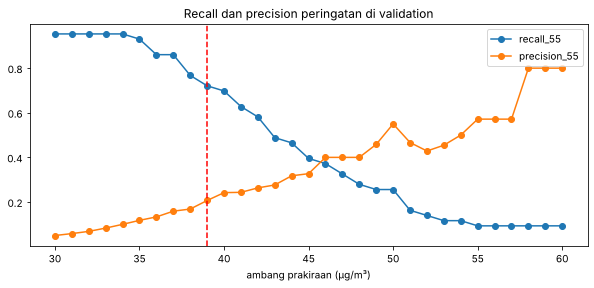

,recall_55,precision_55,jumlah_alarm
model,,,
35,0.930,0.118,340
40,0.698,0.242,124
45,0.395,0.327,52
50,0.256,0.550,20
55,0.093,0.571,7


In [7]:
model = model_hgb(LEARNING_RATE, MAX_ITER).fit(train[FITUR], train["target_pm25"])
pred_val = model.predict(val_eval[FITUR])

kurva = pd.DataFrame([evaluasi(a, y_val, pred_val, ambang=a) for a in range(30, 61)]).set_index("model")
AMBANG = kurva[kurva["recall_55"] >= 0.7].index.max()
print("ambang peringatan:", AMBANG)

kurva[["recall_55", "precision_55"]].plot(figsize=(10, 4), marker="o")
plt.axvline(AMBANG, color="red", linestyle="--")
plt.xlabel("ambang prakiraan (µg/m³)")
plt.title("Recall dan precision peringatan di validation")
plt.show()

kurva.loc[[35, 40, 45, 50, 55], ["recall_55", "precision_55", "jumlah_alarm"]].round(3)

**Pembahasan.** Ambang yang terpilih adalah 39 µg/m³. Peringatan diumumkan kalau prakiraan 3 jam lagi di atas 39. Di validation, ambang ini menangkap 31 dari 43 jam tidak sehat (72%). Sekitar 1 dari 5 peringatan benar-benar menjadi jam tidak sehat. Peringatan yang salah biasanya terjadi saat PM2.5 sudah 40-55 µg/m³, jadi tetap berguna untuk kelompok sensitif.

Karena validation hanya punya 43 jam tidak sehat, ambang ini belum terlalu stabil.

## 5. Fitur yang paling berpengaruh

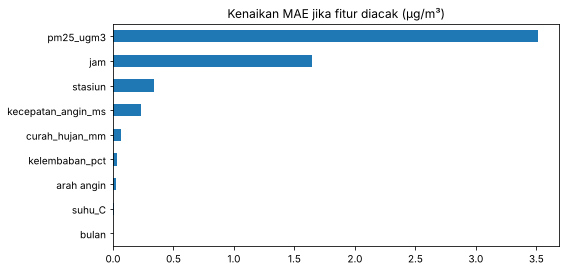

In [8]:
# Permutation importance: seberapa besar MAE naik jika satu fitur diacak
pi = permutation_importance(model, val_eval[FITUR], y_val, scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=42)
pengaruh = pd.Series(pi.importances_mean, index=FITUR)

# Gabungkan sin/cos dan stasiun supaya mudah dibaca
kelompok = {"jam_sin": "jam", "jam_cos": "jam", "bulan_sin": "bulan", "bulan_cos": "bulan",
            "angin_sin": "arah angin", "angin_cos": "arah angin"}
kelompok.update({f"st_{s}": "stasiun" for s in STASIUN})
pengaruh = pengaruh.groupby(lambda f: kelompok.get(f, f)).sum().sort_values()

pengaruh.plot.barh(figsize=(8, 4), title="Kenaikan MAE jika fitur diacak (µg/m³)")
plt.show()

**Pembahasan.** Fitur paling berpengaruh adalah PM2.5 jam ini, diikuti jam, stasiun, kecepatan angin, dan curah hujan. Urutan ini sesuai dengan hasil EDA. Fitur jam membuat model tahu bahwa PM2.5 cenderung naik dari pukul 15 ke 18 dan turun dari pukul 08 ke 11, hal yang tidak bisa dilakukan persistence.

Bulan terlihat tidak berpengaruh karena validation hanya berisi Maret dan April. Ini tidak berarti musim tidak penting.

## 6. Ujian akhir di data test

Model, fitur, parameter, dan ambang sudah ditentukan di bagian 3 dan 4. Model dilatih ulang dengan data train dan
validation, lalu diuji sekali di data test (Mei-Juni 2026). Hasil test tidak dipakai untuk mengubah model.

In [9]:
train_val = pd.concat([train, val])
model_final = model_hgb(LEARNING_RATE, MAX_ITER).fit(train_val[FITUR], train_val["target_pm25"])

test_eval = test[test["pm25_asli"].notna()].copy()
test_eval["prakiraan"] = model_final.predict(test_eval[FITUR])
y_test = test_eval["target_pm25"]

hasil_test = pd.DataFrame([
    evaluasi("Baseline persistence", y_test, test_eval["pm25_asli"]),
    evaluasi("Model final, ambang 55", y_test, test_eval["prakiraan"]),
    evaluasi(f"Model final, ambang {AMBANG}", y_test, test_eval["prakiraan"], ambang=AMBANG),
])
hasil_test.round(3)

,model,MAE,recall_55,precision_55,jumlah_alarm
0,Baseline persistence,6.511,0.301,0.305,236
1,"Model final, ambang 55",4.599,0.326,0.586,133
2,"Model final, ambang 39",4.599,0.937,0.205,1095


In [10]:
# MAE per stasiun
test_eval.groupby("stasiun").apply(lambda g: pd.Series({
    "MAE_persistence": mean_absolute_error(g["target_pm25"], g["pm25_asli"]),
    "MAE_model": mean_absolute_error(g["target_pm25"], g["prakiraan"]),
}), include_groups=False).loc[STASIUN].round(2)

,MAE_persistence,MAE_model
stasiun,,
Dago,4.21,3.13
Soekarno-Hatta,9.66,6.01
Cibeureum,7.30,5.54
Antapani,5.83,4.35
Ujungberung,5.55,3.96


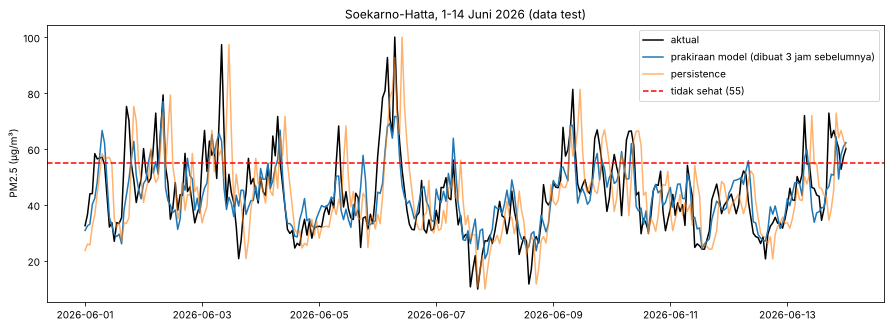

In [11]:
sh = test_eval[(test_eval["stasiun"] == "Soekarno-Hatta") & (test_eval["target_time"].between("2026-06-01", "2026-06-14"))]

plt.figure(figsize=(15, 5))
plt.plot(sh["target_time"], sh["target_pm25"], color="black", label="aktual")
plt.plot(sh["target_time"], sh["prakiraan"], label="prakiraan model (dibuat 3 jam sebelumnya)")
plt.plot(sh["target_time"], sh["pm25_asli"], alpha=0.6, label="persistence")
plt.axhline(55, color="red", linestyle="--", label="tidak sehat (55)")
plt.title("Soekarno-Hatta, 1-14 Juni 2026 (data test)")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.show()

In [12]:
pd.crosstab(
    np.where(y_test > 55, "aktual > 55", "aktual <= 55"),
    np.where(test_eval["prakiraan"] > AMBANG, "peringatan", "tidak ada peringatan"),
    rownames=["aktual"], colnames=["keputusan model"],
)

keputusan model,peringatan,tidak ada peringatan
aktual,,
aktual <= 55,871,6110
aktual > 55,224,15


**Pembahasan.** Di data test, MAE model final 4,60 µg/m³, sedangkan persistence 6,51 µg/m³ (29% lebih baik). Model lebih baik di semua stasiun, paling besar di Soekarno-Hatta (9,66 menjadi 6,01). MAE test tidak lebih buruk dari validation, jadi tidak ada tanda overfitting ke data validation.

Di grafik Soekarno-Hatta, garis persistence selalu tertinggal 3 jam. Prakiraan model lebih cepat mengikuti naik turunnya, tapi puncak yang tajam masih diprakirakan lebih rendah.

Dengan ambang 39, model menangkap 94% jam tidak sehat di test (224 dari 239), dibanding 30% untuk persistence. Tapi jumlah peringatannya 1.095 dalam dua bulan dan hanya 20% yang benar. Penyebabnya, ambang dipilih di musim bersih, sedangkan test ada di awal kemarau. Ambang tidak diubah setelah melihat test. Untuk versi berikutnya, ambang bisa dipilih dengan data yang mencakup musim kemarau atau dibedakan per musim.

## 7. Menyimpan model

In [13]:
Path("artifacts").mkdir(exist_ok=True)
joblib.dump(model_final, "artifacts/model.joblib")

def angka(baris):
    return {"MAE": round(float(baris["MAE"]), 3), "recall_55": round(float(baris["recall_55"]), 3),
            "precision_55": round(float(baris["precision_55"]), 3)}

metadata = {
    "versi_model": "1.0.0",
    "algoritma": "HistGradientBoostingRegressor",
    "parameter": {"learning_rate": LEARNING_RATE, "max_iter": MAX_ITER},
    "fitur_masukan": FITUR,
    "stasiun": STASIUN,
    "rentang_pm25_latih": [float(train_val["pm25_ugm3"].min()), float(train_val["pm25_ugm3"].max())],
    "threshold": {"peringatan_ugm3": int(AMBANG), "alasan": "ambang terbesar dengan recall >= 0.7 di validation"},
    "metrik": {
        "validation": {"baseline_persistence": angka(hasil[0]),
                       "model": angka(evaluasi("", y_val, pred_val, ambang=AMBANG))},
        "test": {"baseline_persistence": angka(hasil_test.iloc[0]), "model": angka(hasil_test.iloc[2])},
    },
}
Path("artifacts/metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(json.dumps(metadata, indent=2))

{
  "versi_model": "1.0.0",
  "algoritma": "HistGradientBoostingRegressor",
  "parameter": {
    "learning_rate": 0.03,
    "max_iter": 600
  },
  "fitur_masukan": [
    "pm25_ugm3",
    "suhu_C",
    "kelembaban_pct",
    "kecepatan_angin_ms",
    "curah_hujan_mm",
    "angin_sin",
    "angin_cos",
    "jam_sin",
    "jam_cos",
    "bulan_sin",
    "bulan_cos",
    "st_Dago",
    "st_Soekarno-Hatta",
    "st_Cibeureum",
    "st_Antapani",
    "st_Ujungberung"
  ],
  "stasiun": [
    "Dago",
    "Soekarno-Hatta",
    "Cibeureum",
    "Antapani",
    "Ujungberung"
  ],
  "rentang_pm25_latih": [
    1.0,
    128.4
  ],
  "threshold": {
    "peringatan_ugm3": 39,
    "alasan": "ambang terbesar dengan recall >= 0.7 di validation"
  },
  "metrik": {
    "validation": {
      "baseline_persistence": {
        "MAE": 6.235,
        "recall_55": 0.186,
        "precision_55": 0.186
      },
      "model": {
        "MAE": 4.673,
        "recall_55": 0.721,
        "precision_55": 0.207
      }

In [14]:
# Contoh prediksi seperti yang dilakukan aplikasi
x = fitur_dari_input("Soekarno-Hatta", "2026-06-10 15:00", pm25=42, suhu=27, kelembaban=70,
                     kecepatan_angin=1.0, arah_angin=90, curah_hujan=0)
prakiraan = model_final.predict(x)[0]
print(f"prakiraan pukul 18:00: {prakiraan:.1f} µg/m³ ({kategori_pm25(prakiraan)})")
print("peringatan:", prakiraan > AMBANG)

prakiraan pukul 18:00: 45.7 µg/m³ (sedang)
peringatan: True


## 8. Ringkasan

| Model | MAE validation | MAE test | Recall >55 test |
|---|---|---|---|
| Baseline persistence | 6,23 | 6,51 | 30% |
| HistGradientBoosting, set A | 4,67 | 4,60 | 94% (ambang 39) |

- Model final: HistGradientBoostingRegressor (learning_rate 0,03, 600 iterasi) dengan 16 fitur kondisi saat ini.
- Threshold peringatan: 39 µg/m³, ambang terbesar dengan recall minimal 70% di validation.
- Kategori mengikuti ISPU: baik <= 15,5, sedang 15,6-55, tidak sehat > 55.
- Model dan metadata disimpan di `artifacts/`.

Keterbatasan:

- Puncak PM2.5 yang mendadak masih diprakirakan terlalu rendah.
- Ambang peringatan menghasilkan banyak peringatan di musim kemarau.
- Data hanya dua tahun.
- Model belum pernah melihat kejadian khusus seperti kebakaran.

Jika dipakai sungguhan, MAE mingguan dan ketepatan peringatan perlu dipantau, dan model dilatih ulang secara berkala.